<a href="https://colab.research.google.com/github/JonerciJon/CSST106/blob/main/Lab_1_Experiment_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload a sample color image (JPG/PNG), or cancel to use a synthetic image:


Saving 14.jpg to 14.jpg

--- PART 1: LOAD & EXPLORE IMAGE ---
Image Shape (H, W, C): (720, 1280, 3)
Height: 720 px | Width: 1280 px | Channels: 3
Note: OpenCV loads color images in BGR (Blue, Green, Red) order, not RGB.

Original Color Image:


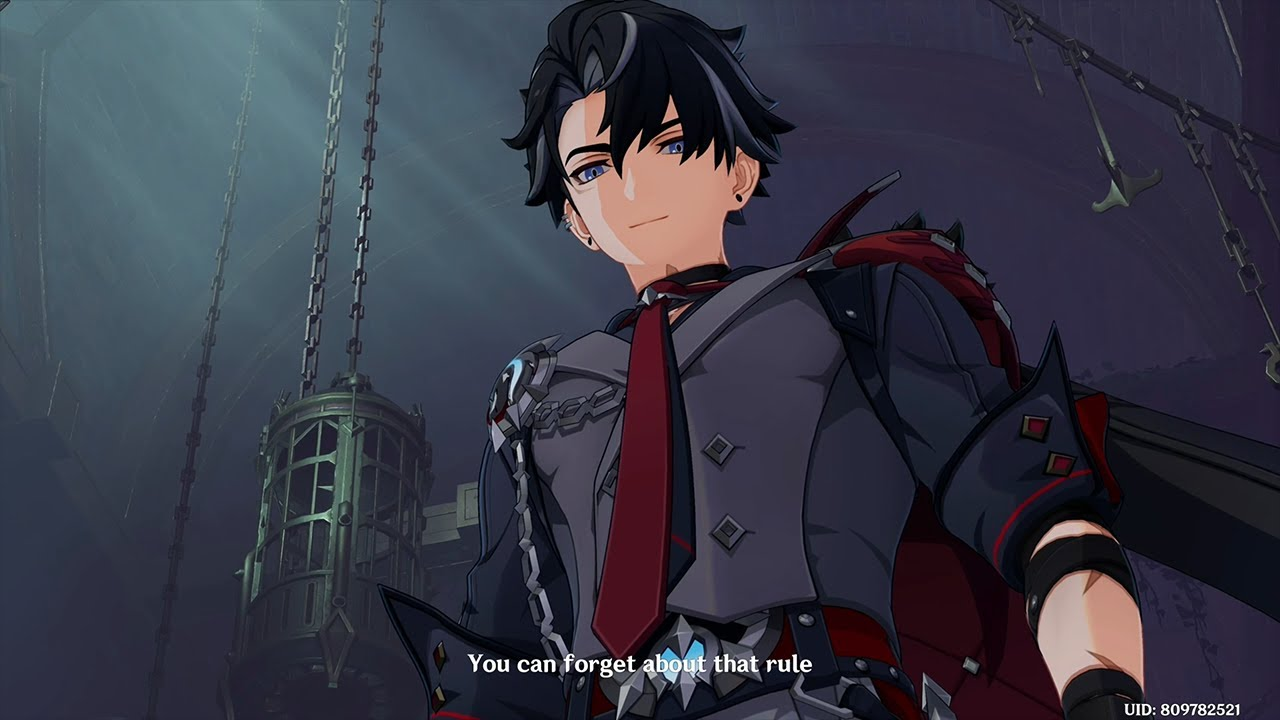


Grayscale Shape (H, W): (720, 1280) (Single channel: intensity 0-255)
Grayscale Image:


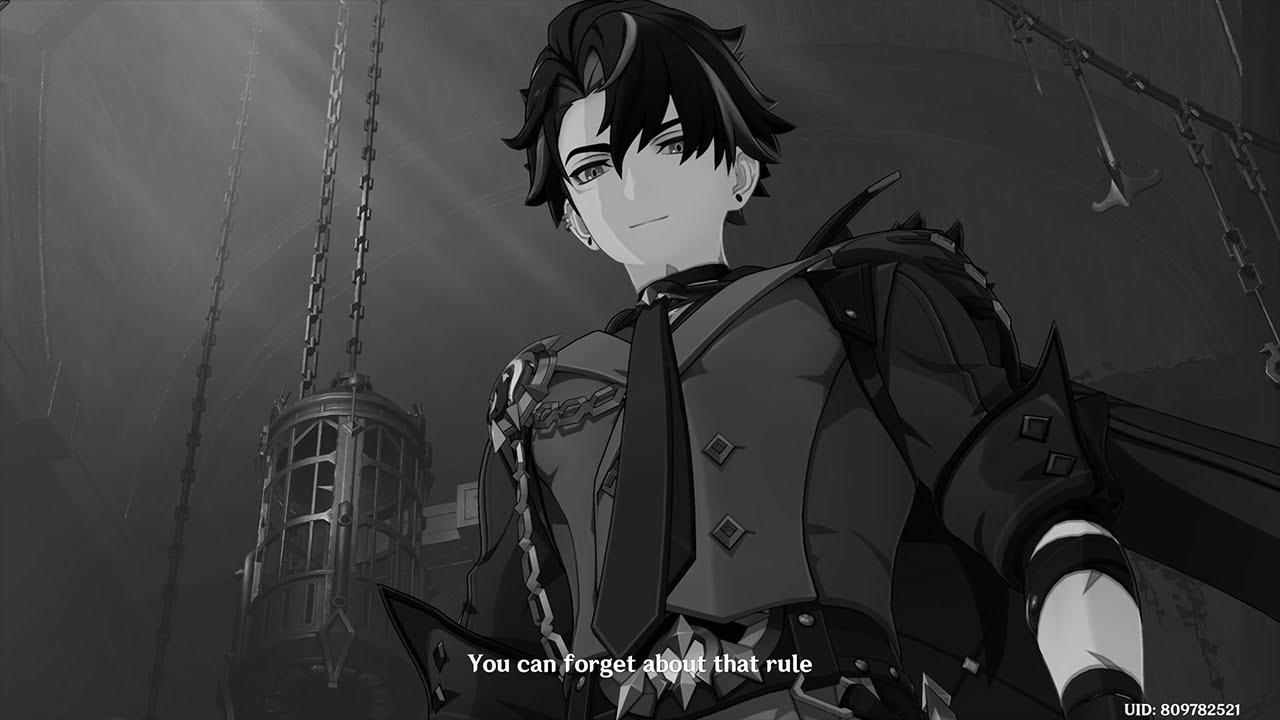


Pixel at (y=150, x=200) -> BGR: [123 115  86] | Grayscale intensity: 107
Modified pixel at (150, 200) to BGR [255, 0, 255]: [255   0 255]
Image with Modified Pixel Patch:


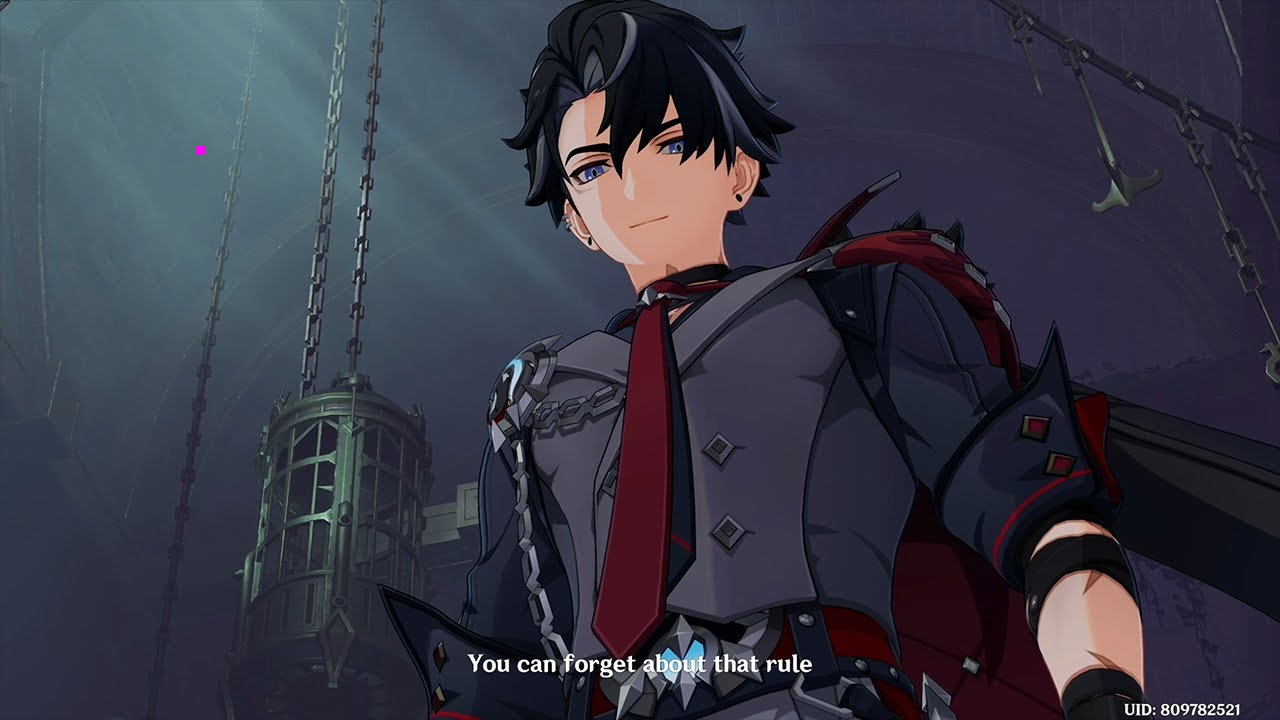


--- PART 2: BASIC IMAGE OPERATIONS ---
Cropped ROI shape: (432, 768, 3)
Cropped Image (ROI):


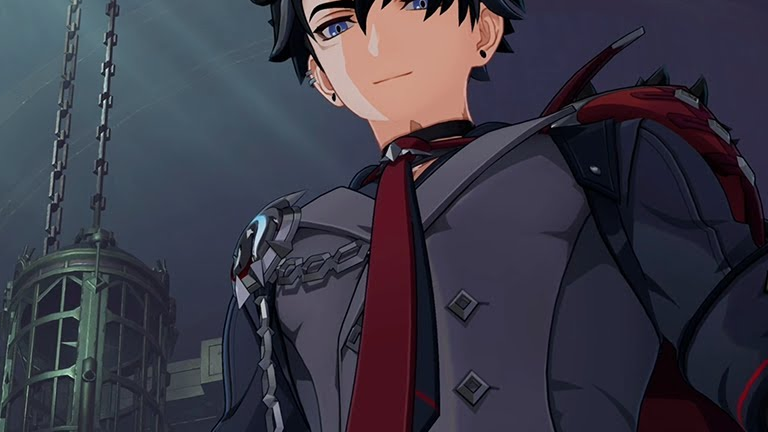

Resized (Smaller 0.5x) shape: (360, 640, 3)
Resized (Larger 1.25x) shape: (900, 1600, 3)
Resized Image (Smaller - 0.5x):


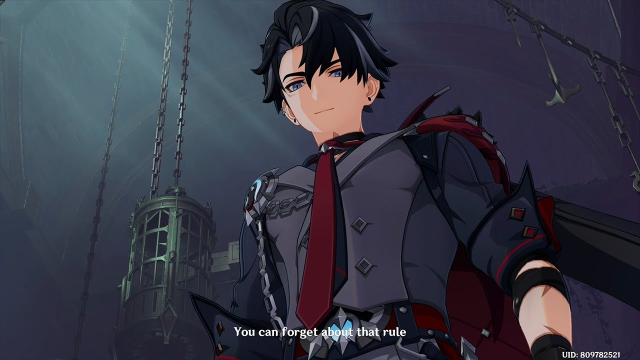

Resized Image (Larger - 1.25x):


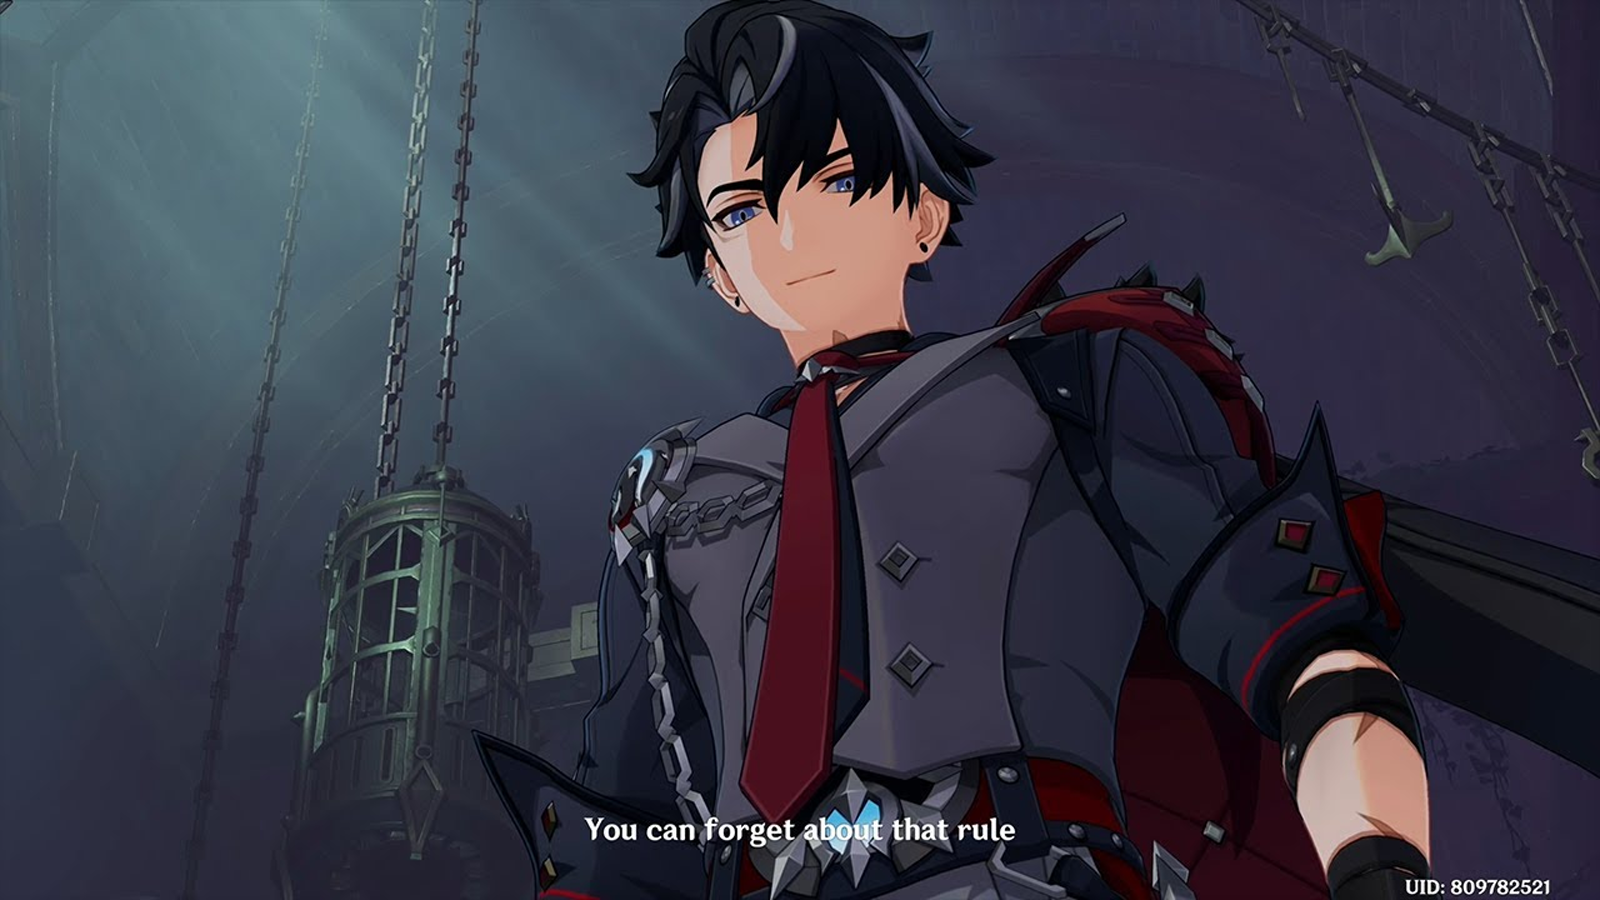

Rotated 90° Clockwise shape: (1280, 720, 3) (Width and Height swap)
Rotated Image (90° Clockwise):


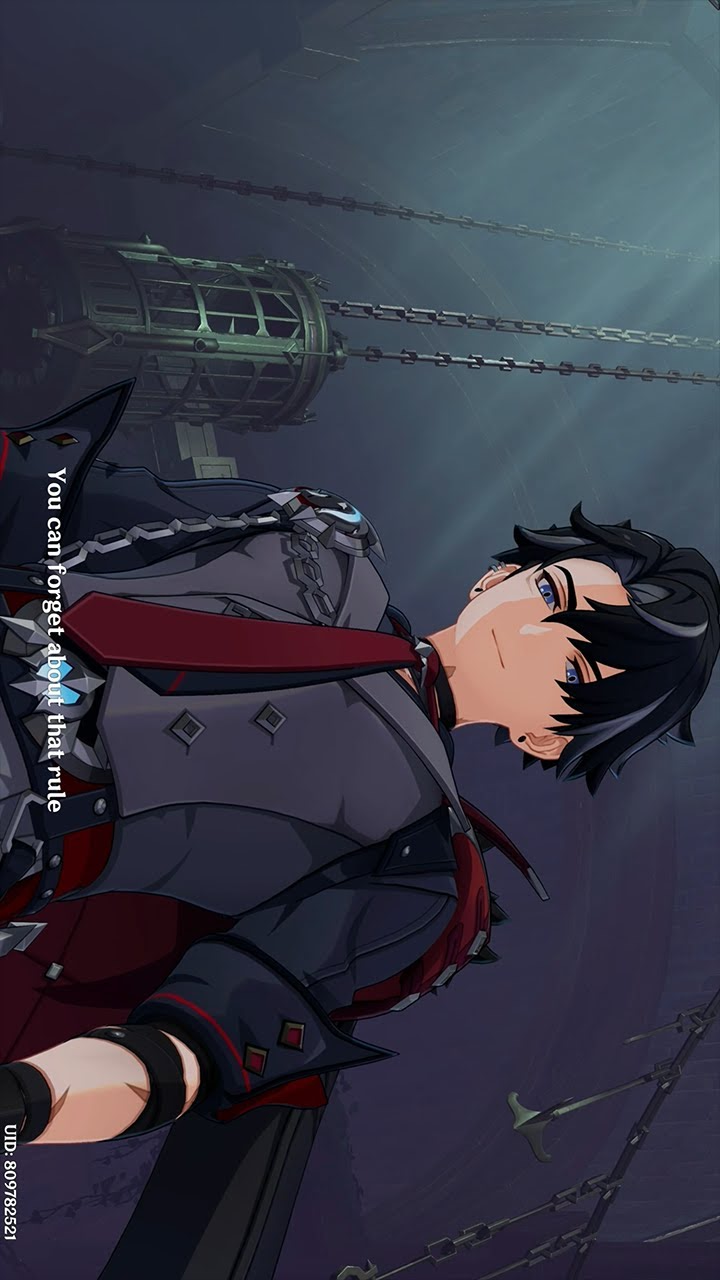

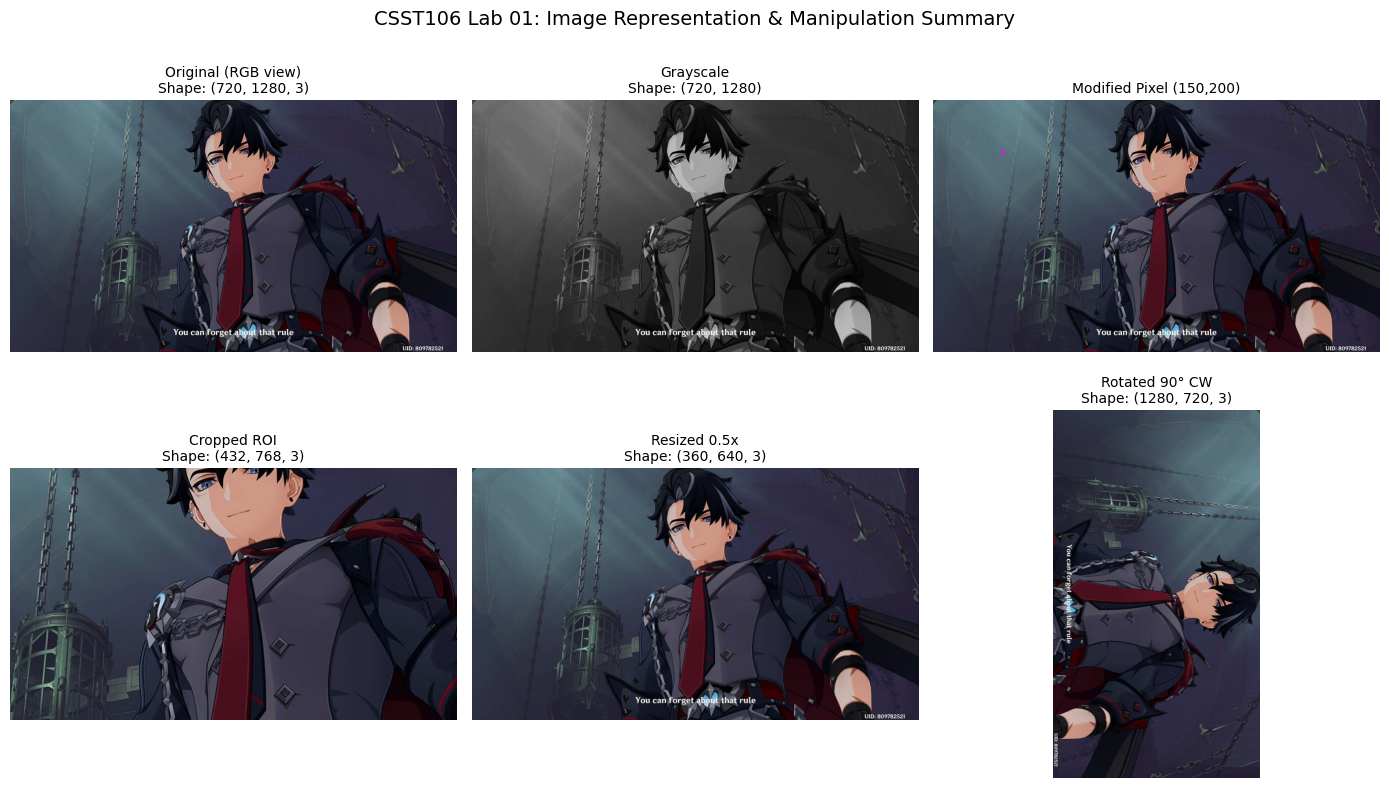

In [1]:
# ==============================================================================
# CSST106 - Laboratory Exercise No. 1: Image Manipulation
# Colab-compatible OpenCV script (uses cv2_imshow instead of cv2.imshow)
# ==============================================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
from google.colab import files

# ------------------------------------------------------------------------------
# STEP 0: Load a Sample Image (Upload your own or generate a fallback test image)
# ------------------------------------------------------------------------------
print("Upload a sample color image (JPG/PNG), or cancel to use a synthetic image:")
try:
    uploaded = files.upload()
    image_path = next(iter(uploaded))
    img = cv2.imread(image_path)
    assert img is not None, "Failed to read uploaded image."
except Exception:
    print("No file uploaded; generating a synthetic color sample image (400x600)...")
    img = np.zeros((400, 600, 3), dtype=np.uint8)
    # Blue-to-red gradient background (BGR format)
    img[:, :, 0] = np.tile(np.linspace(220, 40, 600, dtype=np.uint8), (400, 1))
    img[:, :, 2] = np.tile(np.linspace(40, 230, 600, dtype=np.uint8), (400, 1))
    # Add geometric shapes for clear ROI, rotation, and pixel inspection
    cv2.rectangle(img, (120, 90), (480, 310), (0, 220, 220), thickness=-1)  # Yellow box
    cv2.circle(img, (300, 200), 75, (0, 180, 0), thickness=-1)               # Green circle
    cv2.putText(img, "CSST106", (225, 210), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 2)

# ==============================================================================
# PART 1: UNDERSTANDING DIGITAL IMAGES
# ==============================================================================
print("\n--- PART 1: LOAD & EXPLORE IMAGE ---")

# 1. Inspect dimensions and BGR ordering
height, width, channels = img.shape
print(f"Image Shape (H, W, C): {img.shape}")
print(f"Height: {height} px | Width: {width} px | Channels: {channels}")
print("Note: OpenCV loads color images in BGR (Blue, Green, Red) order, not RGB.")

print("\nOriginal Color Image:")
cv2_imshow(img)

# 2. Convert to Grayscale (single intensity channel: 0 to 255)
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print(f"\nGrayscale Shape (H, W): {gray_img.shape} (Single channel: intensity 0-255)")
print("Grayscale Image:")
cv2_imshow(gray_img)

# 3. Explore Pixel Properties (examine and modify a pixel)
y_coord, x_coord = min(150, height - 1), min(200, width - 1)
bgr_pixel = img[y_coord, x_coord]
gray_pixel = gray_img[y_coord, x_coord]
print(f"\nPixel at (y={y_coord}, x={x_coord}) -> BGR: {bgr_pixel} | Grayscale intensity: {gray_pixel}")

# Modify a small 9x9 patch around (y_coord, x_coord) in bright magenta (B=255, G=0, R=255)
# (A small patch is easy to spot in screenshots while preserving the rest of the image)
img_modified = img.copy()
y1, y2 = max(0, y_coord - 4), min(height, y_coord + 5)
x1, x2 = max(0, x_coord - 4), min(width, x_coord + 5)
img_modified[y1:y2, x1:x2] = [255, 0, 255]

print(f"Modified pixel at ({y_coord}, {x_coord}) to BGR [255, 0, 255]: {img_modified[y_coord, x_coord]}")
print("Image with Modified Pixel Patch:")
cv2_imshow(img_modified)

# ==============================================================================
# PART 2: BASIC IMAGE OPERATIONS
# ==============================================================================
print("\n--- PART 2: BASIC IMAGE OPERATIONS ---")

# 1. Crop a Region of Interest (ROI) -> img[y_start:y_end, x_start:x_end]
roi_y1, roi_y2 = int(height * 0.2), int(height * 0.8)
roi_x1, roi_x2 = int(width * 0.2), int(width * 0.8)
cropped_img = img[roi_y1:roi_y2, roi_x1:roi_x2]
print(f"Cropped ROI shape: {cropped_img.shape}")
print("Cropped Image (ROI):")
cv2_imshow(cropped_img)

# 2. Resize Image (downscale to 50% and upscale to 125%)
resized_small = cv2.resize(img, (width // 2, height // 2), interpolation=cv2.INTER_AREA)
resized_large = cv2.resize(img, (int(width * 1.25), int(height * 1.25)), interpolation=cv2.INTER_CUBIC)
print(f"Resized (Smaller 0.5x) shape: {resized_small.shape}")
print(f"Resized (Larger 1.25x) shape: {resized_large.shape}")
print("Resized Image (Smaller - 0.5x):")
cv2_imshow(resized_small)
print("Resized Image (Larger - 1.25x):")
cv2_imshow(resized_large)

# 3. Rotate Image by 90 degrees (Clockwise)
rotated_90_cw = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
print(f"Rotated 90° Clockwise shape: {rotated_90_cw.shape} (Width and Height swap)")
print("Rotated Image (90° Clockwise):")
cv2_imshow(rotated_90_cw)

# ==============================================================================
# SUMMARY GRID FOR YOUR HARDCOPY REPORT SCREENSHOTS
# ==============================================================================
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle("CSST106 Lab 01: Image Representation & Manipulation Summary", fontsize=14)

panels = [
    (cv2.cvtColor(img, cv2.COLOR_BGR2RGB), f"Original (RGB view)\nShape: {img.shape}", None),
    (gray_img, f"Grayscale\nShape: {gray_img.shape}", "gray"),
    (cv2.cvtColor(img_modified, cv2.COLOR_BGR2RGB), f"Modified Pixel ({y_coord},{x_coord})", None),
    (cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB), f"Cropped ROI\nShape: {cropped_img.shape}", None),
    (cv2.cvtColor(resized_small, cv2.COLOR_BGR2RGB), f"Resized 0.5x\nShape: {resized_small.shape}", None),
    (cv2.cvtColor(rotated_90_cw, cv2.COLOR_BGR2RGB), f"Rotated 90° CW\nShape: {rotated_90_cw.shape}", None),
]

for ax, (data, title, cmap) in zip(axes.flat, panels):
    ax.imshow(data, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.savefig("lab01_summary_grid.png", dpi=150)
plt.show()